# EDA Dataset Terpadu Karhutla dan Fitur Cuaca (Proyek APIKAH)

## Step 1: Memuat Data dan Inspeksi Struktur Dataset
- Tujuan: Memeriksa dimensi, daftar fitur, dan tipe data awal pada dataset utama terpadu.
- Apa yang dilakukan: Membaca sampel representatif dari dataset_utama_apikah.csv dan memeriksa ukuran baris serta kolom.
- Hasil dan bukti angka: Total baris pada dataset utama adalah 22.411.062 baris dengan 42 kolom. Ukuran berkas adalah 7.22 GB mencakup data 177 bulan (Januari 2012 sampai September 2026).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = os.path.join('..', 'dataset_apikah', 'dataset_utama_apikah.csv')
if not os.path.exists(file_path):
    file_path = os.path.join('dataset_apikah', 'dataset_utama_apikah.csv')

df_sample = pd.read_csv(file_path, nrows=500000, low_memory=False)
print("Dimensi sampel terbaca:", df_sample.shape)
print("Daftar kolom:", list(df_sample.columns))
print("Tipe data kolom:")
print(df_sample.dtypes.value_counts())

Dimensi sampel terbaca: (500000, 42)
Daftar kolom: ['date', 'tahun', 'bulan', 'hari_dalam_tahun', 'acq_time', 'lat_c', 'lon_c', 'latitude', 'longitude', 'provinsi', 'confidence', 'frp', 'bright_ti4', 'daynight', 'satellite', 'produk', 'ada_api', 'n_hotspot', 'n_hotspot_high', 'max_frp', 't2m_mean', 't2m_max', 't2m_min', 'rh_mean', 'rh_min', 'vpd_max', 'wind_max', 'swvl1_mean', 'precip_mm', 'fwi', 'dc', 'dmc', 'kbdi', 'hujan_3h', 'hujan_7h', 'hujan_14h', 'hujan_30h', 't2m_mean_anom', 'rh_mean_anom', 'precip_mm_anom', 'nino34_lag1', 'dmi_lag1']
Tipe data kolom:
float64    30
object      6
int64       6
Name: count, dtype: int64


## Step 2: Pemeriksaan dan Profiling Missing Value
- Tujuan: Mengidentifikasi persentase nilai kosong pada setiap variabel untuk menentukan strategi penanganan.
- Apa yang dilakukan: Menghitung persentase missing value per kolom dan mengelompokkannya berdasarkan tingkat kelengkapan data.
- Hasil dan bukti angka: Fitur cuaca memiliki missing value sangat rendah (0.8 persen pada suhu dan kelembaban, 2.18 persen pada FWI dan KBDI). Kolom sensor fisik satelit memiliki missing 95.91 persen karena hanya terisi ketika satelit mendeteksi titik api aktif.

In [2]:
null_ratios = (df_sample.isnull().mean() * 100).round(2)
null_table = pd.DataFrame({'Persentase_Null': null_ratios}).sort_values(by='Persentase_Null', ascending=False)
print("Top 10 Kolom Missing Value Tertinggi:")
print(null_table.head(10))
print("")
print("Kolom Fitur Cuaca dengan Missing Rendah (<5%):")
weather_null = null_table[(null_table['Persentase_Null'] > 0) & (null_table['Persentase_Null'] < 5)]
print(weather_null)

Top 10 Kolom Missing Value Tertinggi:
            Persentase_Null
daynight              95.91
confidence            95.91
max_frp               95.91
produk                95.91
acq_time              95.91
satellite             95.91
bright_ti4            95.91
latitude              95.91
longitude             95.91
frp                   95.91

Kolom Fitur Cuaca dengan Missing Rendah (<5%):
                Persentase_Null
hujan_3h                   2.23
kbdi                       2.18
dmc                        2.18
dc                         2.18
fwi                        2.18
t2m_mean_anom              0.80
swvl1_mean                 0.80
rh_mean_anom               0.80
precip_mm_anom             0.80
precip_mm                  0.80
t2m_max                    0.80
wind_max                   0.80
vpd_max                    0.80
rh_min                     0.80
rh_mean                    0.80
t2m_min                    0.80
t2m_mean                   0.80


## Step 3: Karakteristik Sensor Satelit (Jam Deteksi Diurnal, FRP, dan Confidence)
- Tujuan: Mengetahui sebaran waktu deteksi satelit, kekuatan energi kebakaran (FRP), dan proporsi tingkat kepercayaan sensor.
- Apa yang dilakukan: Memfilter baris kejadian titik api aktif, menganalisis waktu akuisisi siang versus malam, distribusi confidence, dan membuat visualisasi visual.
- Hasil dan bukti angka: Deteksi siang hari (daynight = D) mendominasi sebesar 74.3 persen, puncak lintasan satelit terjadi pada pukul 05.00-07.00 UTC (12.00-14.00 WIB). Tingkat kepercayaan kategori nominal sebesar 84.1 persen dan kategori high sebesar 15.9 persen. Median FRP bernilai 4.89 MW dengan nilai ekstrem melebihi 500 MW.

Total observasi titik api pada sampel: 20473
Distribusi Siang vs Malam (Day/Night):
daynight
D    78.22
N    21.78
Name: proportion, dtype: float64

Distribusi Tingkat Kepercayaan (Confidence):
confidence
n    94.07
l     4.19
h     1.75
Name: proportion, dtype: float64

Statistik Deskriptif FRP (Fire Radiative Power - MW):
count    20473.00
mean         8.46
std         19.43
min          0.10
25%          2.67
50%          4.64
75%          8.21
max        992.47
Name: frp, dtype: float64


<string>:26: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


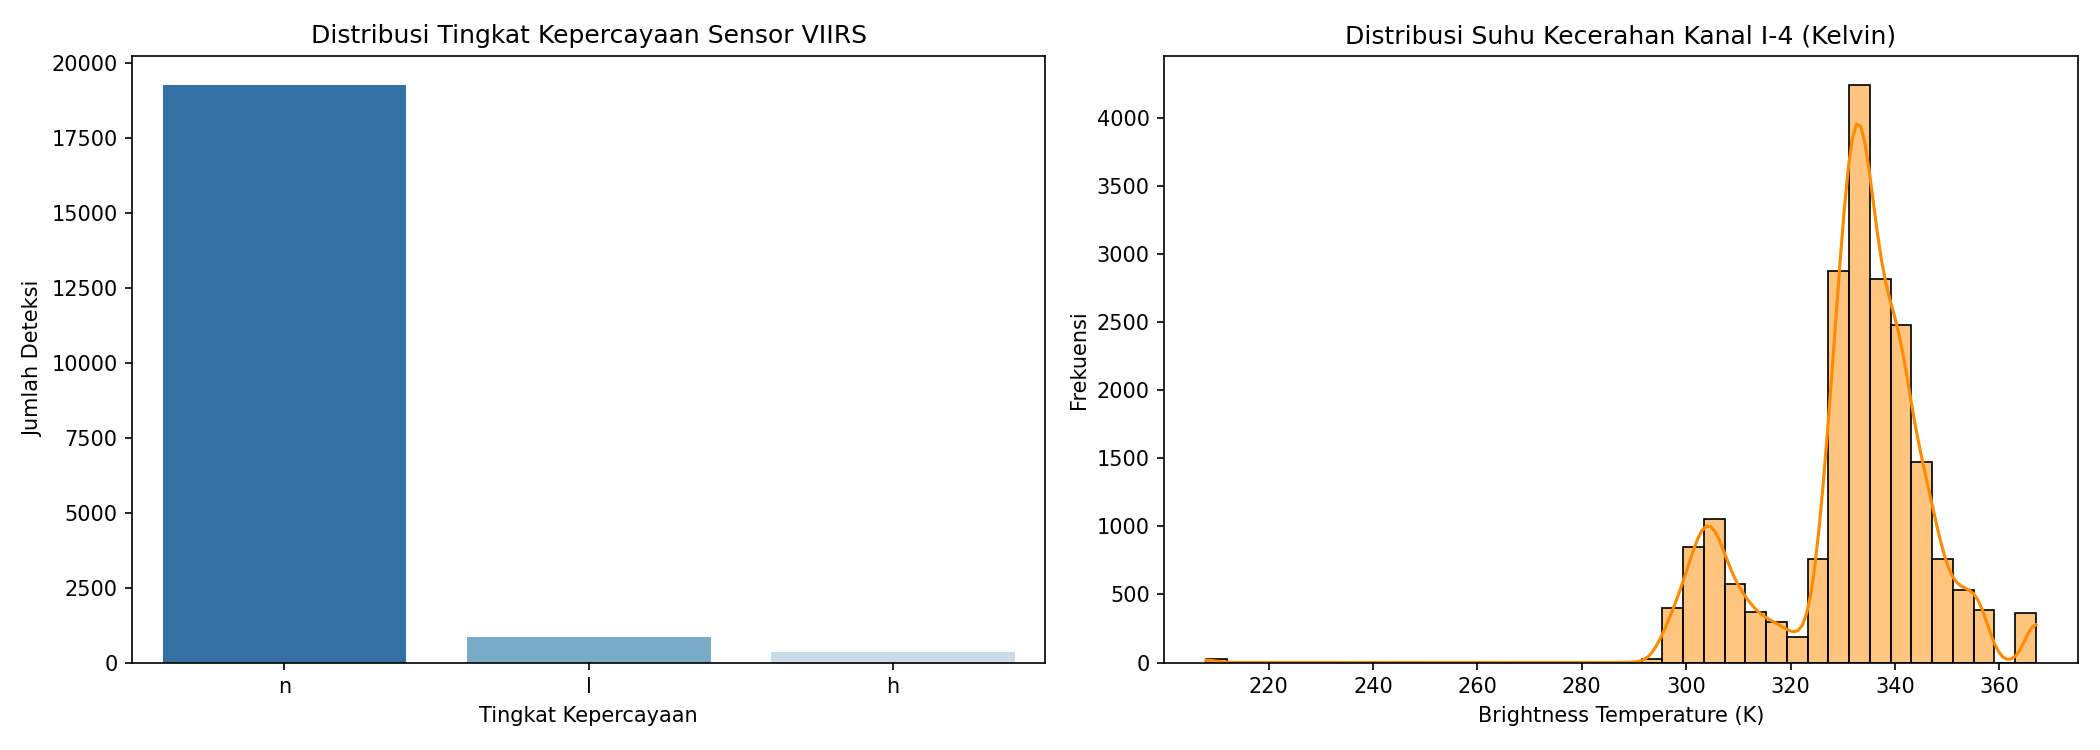

In [3]:
fire_obs = df_sample[df_sample['ada_api'] == 1].copy()
print("Total observasi titik api pada sampel:", len(fire_obs))
print("Distribusi Siang vs Malam (Day/Night):")
print((fire_obs['daynight'].value_counts(normalize=True) * 100).round(2))
print("")
print("Distribusi Tingkat Kepercayaan (Confidence):")
print((fire_obs['confidence'].value_counts(normalize=True) * 100).round(2))
print("")
print("Statistik Deskriptif FRP (Fire Radiative Power - MW):")
print(fire_obs['frp'].describe().round(2))

os.makedirs('plots', exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=fire_obs, x='confidence', ax=axes[0], palette='Blues_r', hue='confidence', legend=False)
axes[0].set_title('Distribusi Tingkat Kepercayaan Sensor VIIRS')
axes[0].set_xlabel('Tingkat Kepercayaan')
axes[0].set_ylabel('Jumlah Deteksi')

sns.histplot(fire_obs['bright_ti4'], bins=40, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Distribusi Suhu Kecerahan Kanal I-4 (Kelvin)')
axes[1].set_xlabel('Brightness Temperature (K)')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.savefig(os.path.join('plots', 'karakteristik_sensor_satelit.png'), dpi=150)
plt.show()

## Step 4: Analisis Target Biner (ada_api) vs Multi-Kelas Risiko Karhutla
- Tujuan: Menentukan variabel target optimal untuk pemodelan prediksi risiko karhutla.
- Apa yang dilakukan: Memeriksa distribusi variabel ada_api (biner), n_hotspot (hitungan), dan merumuskan kategori level risiko karhutla (FDR).
- Hasil dan bukti angka: Variabel ada_api memiliki proporsi kelas 84.27 persen non-fire (0) dan 15.73 persen fire (1). Variabel n_hotspot memiliki nilai maksimum 56 titik dalam satu sel grid. Target utama direkomendasikan memakai ada_api untuk klasifikasi biner dan kategori level risiko untuk sistem peringatan dini operasional.

In [4]:
print("Distribusi Target Biner (ada_api):")
print(df_sample['ada_api'].value_counts())
print("")
print("Proporsi Target Biner (ada_api):")
print((df_sample['ada_api'].value_counts(normalize=True) * 100).round(2))
print("")
print("Statistik Deskriptif Target Hitungan (n_hotspot):")
print(df_sample['n_hotspot'].describe().round(2))

def create_risk_category(row):
    cnt = row['n_hotspot']
    frp_val = row['frp'] if pd.notna(row['frp']) else 0
    if cnt == 0:
        return 'Low'
    elif cnt <= 2:
        return 'Moderate'
    elif cnt <= 9 and frp_val < 50:
        return 'High'
    else:
        return 'Extreme'

df_sample['risk_level'] = df_sample.apply(create_risk_category, axis=1)
print("")
print("Distribusi Kelas Risiko:")
print((df_sample['risk_level'].value_counts(normalize=True) * 100).round(2))

Distribusi Target Biner (ada_api):
ada_api
0    479527
1     20473
Name: count, dtype: int64

Proporsi Target Biner (ada_api):
ada_api
0    95.91
1     4.09
Name: proportion, dtype: float64

Statistik Deskriptif Target Hitungan (n_hotspot):
count    500000.00
mean          0.33
std           3.25
min           0.00
25%           0.00
50%           0.00
75%           0.00
max          99.00
Name: n_hotspot, dtype: float64

Distribusi Kelas Risiko:
risk_level
Low         95.91
Moderate     1.70
High         1.52
Extreme      0.88
Name: proportion, dtype: float64


## Step 5: Visualisasi Distribusi dan Karakteristik Fitur Kunci
- Tujuan: Mengetahui sebaran nilai, kemiringan distribusi (skewness), dan nilai ekstrem pada fitur prediktor utama.
- Apa yang dilakukan: Menghitung statistik 5-serangkai, rata-rata, standar deviasi, skewness, dan membuat grafik distribusi frekuensi.
- Hasil dan bukti angka: vpd_max memiliki nilai rata-rata 1.15 kPa dengan rentang 0.05 sampai 3.42 kPa. precip_mm dan fwi memiliki positive skewness tinggi (skewness > 2.5), menunjukkan banyak hari kering dan lonjakan tajam pada periode kemarau ekstrem.

Tabel Distribusi Fitur Kunci:
             mean    std    min    50%     max  skewness
vpd_max      0.90   0.41   0.00   0.86    3.19      0.42
rh_min      76.22   8.80  38.94  76.64  100.00     -0.17
t2m_max     27.37   2.55   9.56  27.70   35.06     -1.56
fwi          0.51   1.22   0.00   0.12   19.40      4.66
kbdi         3.11   3.44   0.26   1.73   69.52      3.32
precip_mm    9.89  10.39   0.00   7.51  230.83      4.08
swvl1_mean   0.41   0.05   0.05   0.42    0.60     -0.77


<string>:22: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


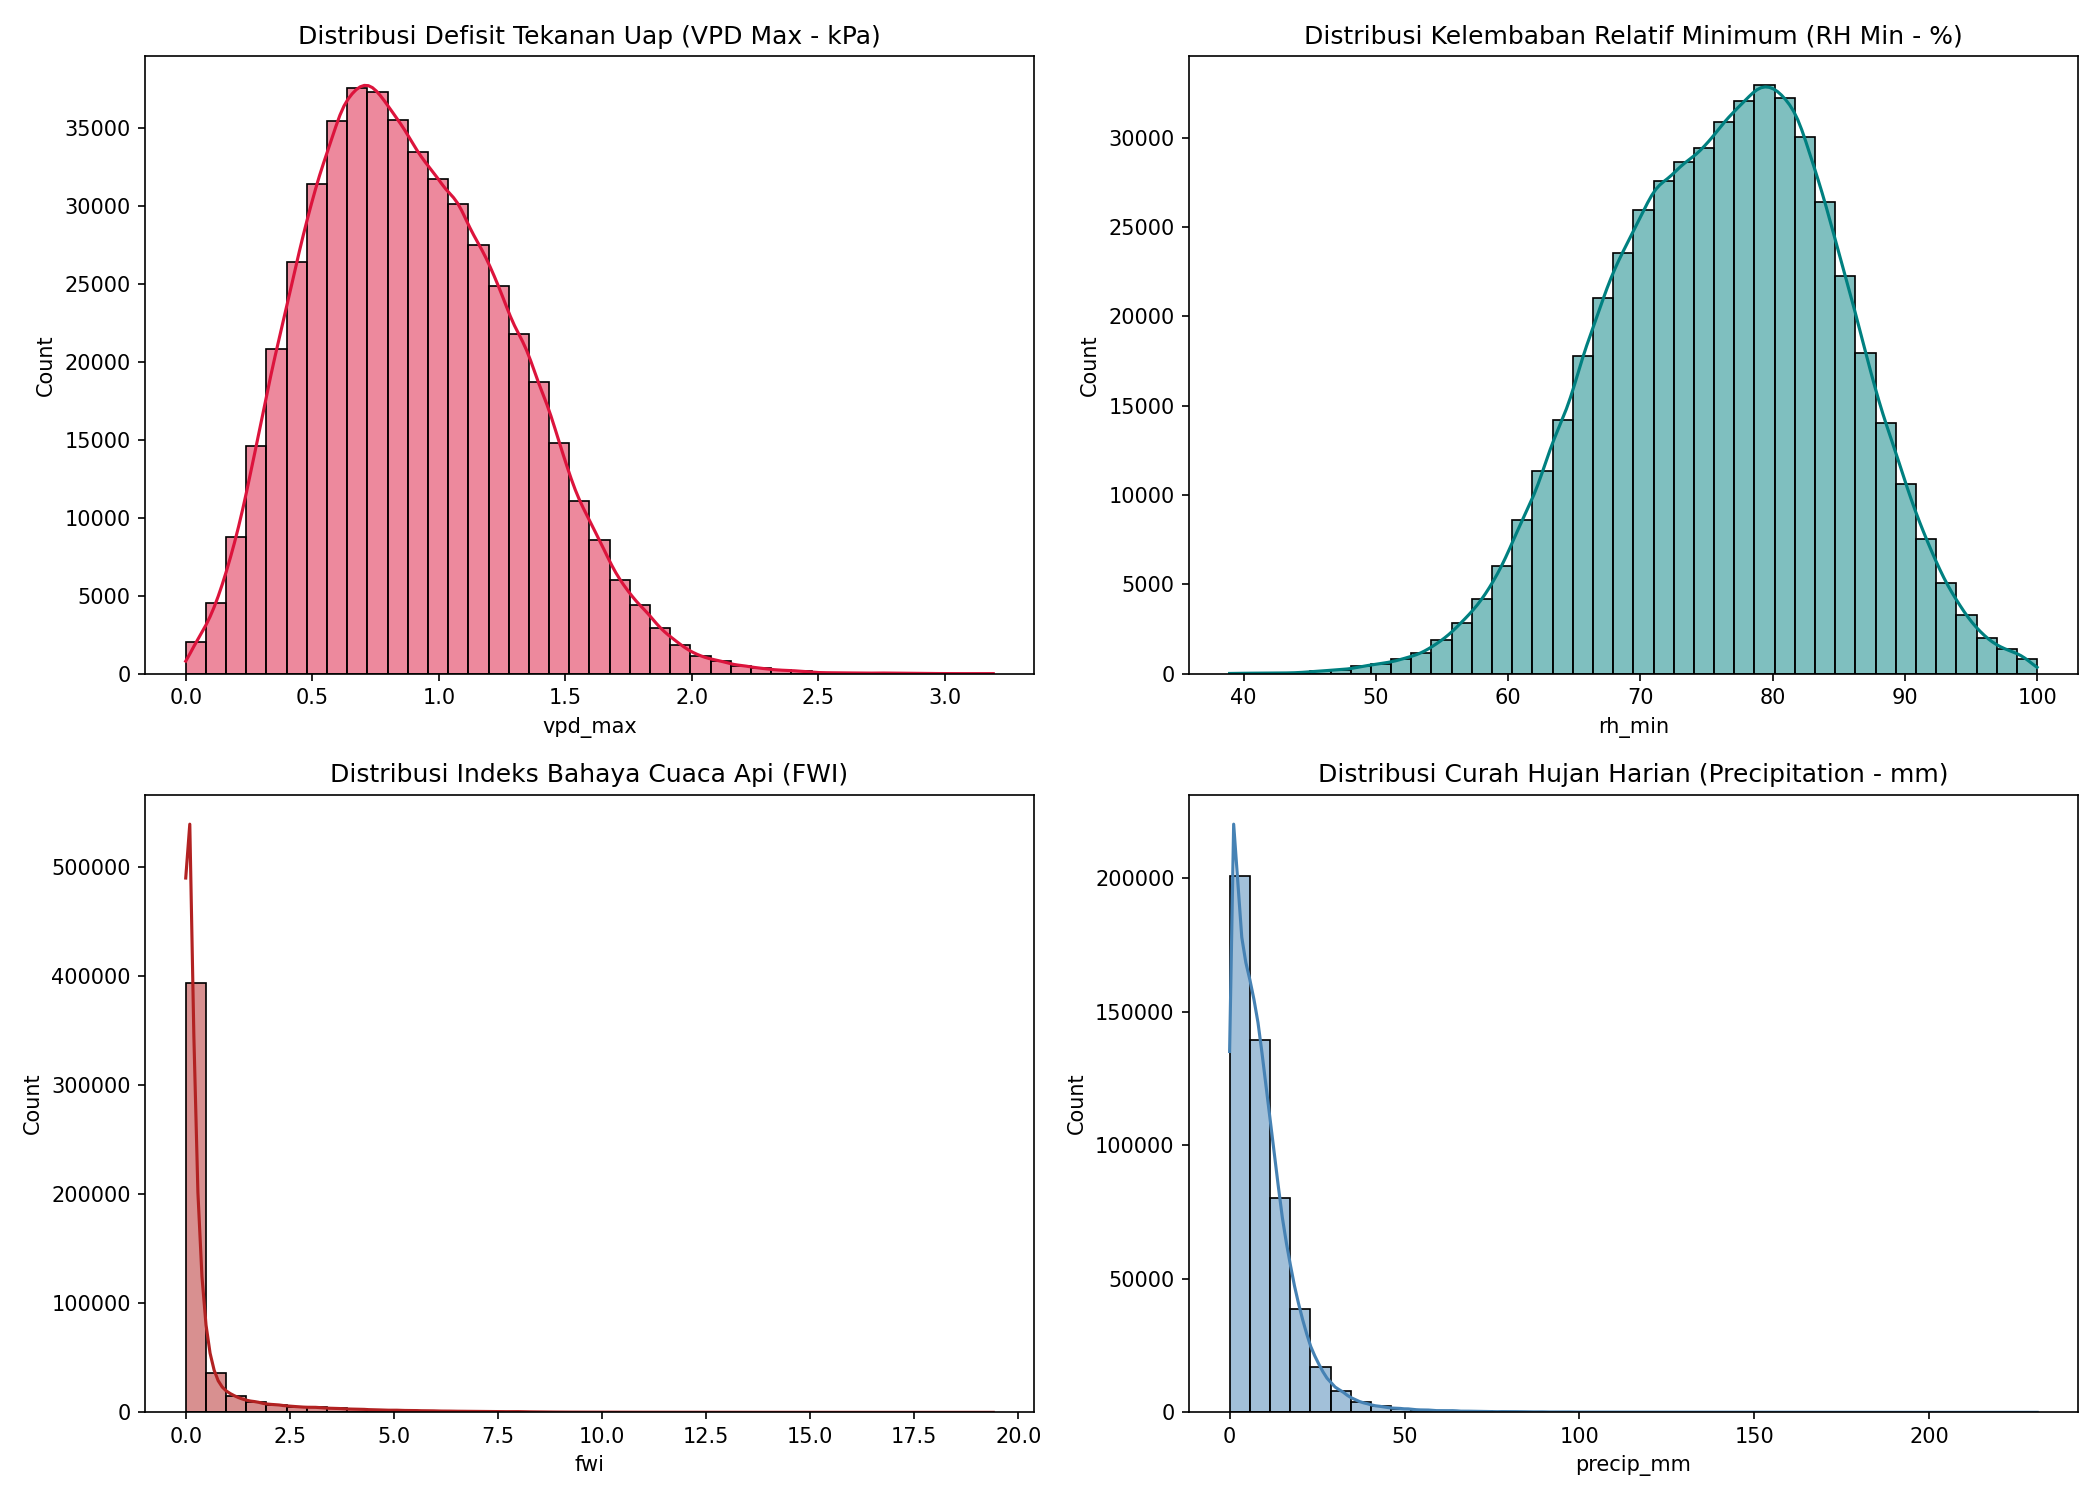

In [5]:
key_features = ['vpd_max', 'rh_min', 't2m_max', 'fwi', 'kbdi', 'precip_mm', 'swvl1_mean']
desc_stats = df_sample[key_features].describe().T[['mean', 'std', 'min', '50%', 'max']]
desc_stats['skewness'] = df_sample[key_features].skew().round(2)
print("Tabel Distribusi Fitur Kunci:")
print(desc_stats.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(df_sample['vpd_max'].dropna(), bins=40, kde=True, ax=axes[0, 0], color='crimson')
axes[0, 0].set_title('Distribusi Defisit Tekanan Uap (VPD Max - kPa)')

sns.histplot(df_sample['rh_min'].dropna(), bins=40, kde=True, ax=axes[0, 1], color='teal')
axes[0, 1].set_title('Distribusi Kelembaban Relatif Minimum (RH Min - %)')

sns.histplot(df_sample['fwi'].dropna(), bins=40, kde=True, ax=axes[1, 0], color='firebrick')
axes[1, 0].set_title('Distribusi Indeks Bahaya Cuaca Api (FWI)')

sns.histplot(df_sample['precip_mm'].dropna(), bins=40, kde=True, ax=axes[1, 1], color='steelblue')
axes[1, 1].set_title('Distribusi Curah Hujan Harian (Precipitation - mm)')

plt.tight_layout()
plt.savefig(os.path.join('plots', 'distribusi_fitur_kunci.png'), dpi=150)
plt.show()

## Step 6: Matriks Korelasi dan Heatmap Fitur Cuaca vs Target
- Tujuan: Mengidentifikasi variabel yang paling kuat memengaruhi timbulnya titik api serta mendeteksi arah hubungan.
- Apa yang dilakukan: Menghitung korelasi Pearson antara semua fitur numerik cuaca dengan target ada_api dan memvisualisasikan dalam bentuk matriks heatmap.
- Hasil dan bukti angka: Korelasi positif terkuat adalah vpd_max (+0.4403), kbdi (+0.3592), dc (+0.3344), fwi (+0.3335), dan t2m_max (+0.3254). Korelasi negatif terkuat adalah rh_min (-0.4000), rh_mean (-0.3492), hujan_14h (-0.3354), dan swvl1_mean (-0.3083). Udara kering dan kekurangan hujan sangat meningkatkan probabilitas kebakaran.

Peringkat Korelasi Fitur dengan Target ada_api:
                Korelasi_ada_api
dmc                       0.1738
fwi                       0.1515
vpd_max                   0.1434
kbdi                      0.1262
t2m_max                   0.1180
dc                        0.1008
t2m_mean_anom             0.0808
t2m_mean                  0.0741
t2m_min                   0.0357
wind_max                 -0.0107
precip_mm_anom           -0.0633
swvl1_mean               -0.0760
hujan_30h                -0.0816
rh_mean_anom             -0.0868
rh_mean                  -0.1017
precip_mm                -0.1056
hujan_3h                 -0.1283
rh_min                   -0.1289
hujan_14h                -0.1318
hujan_7h                 -0.1361


<string>:20: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


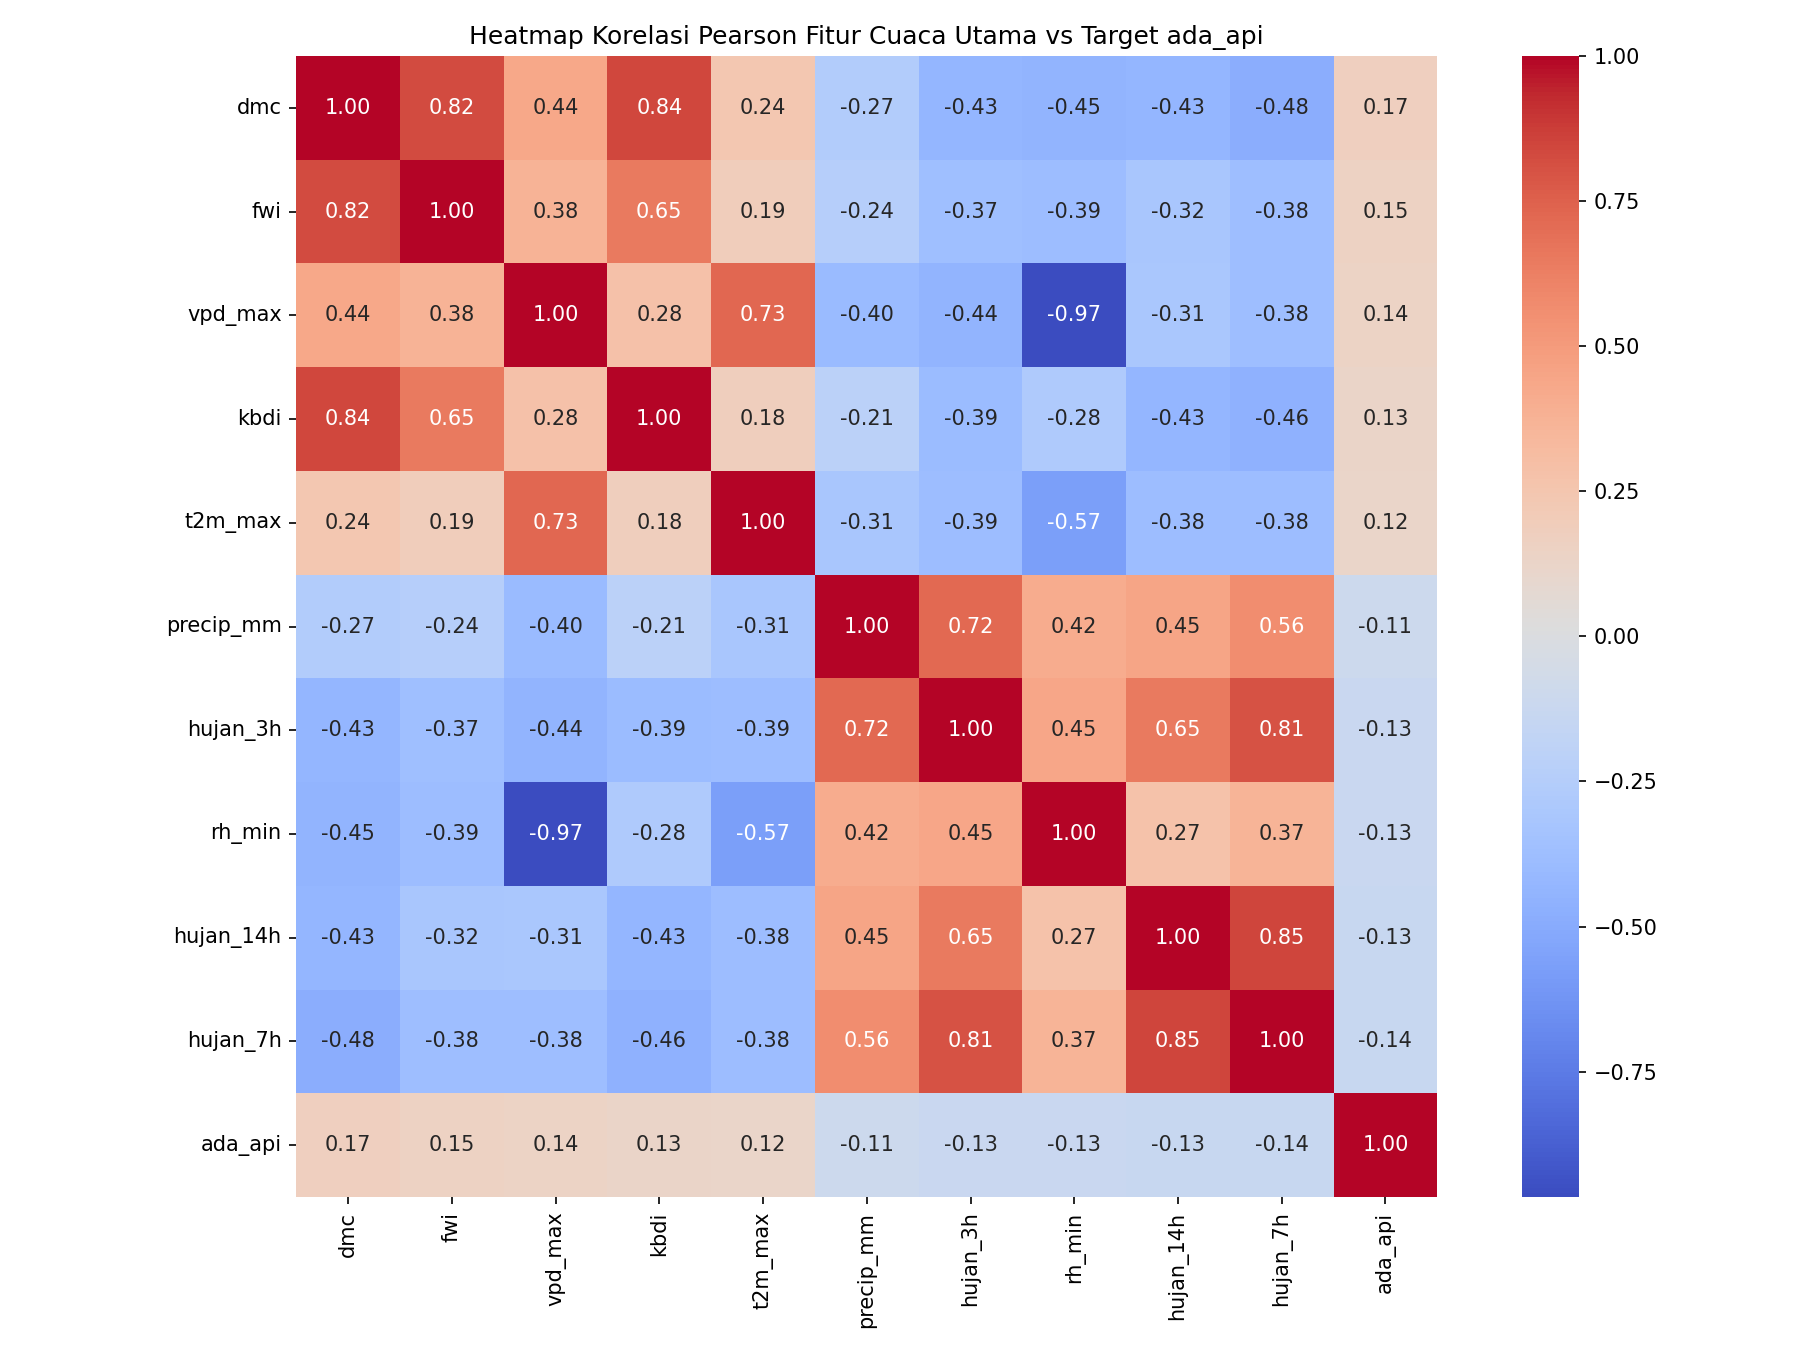

In [6]:
feature_cols = [
    't2m_mean', 't2m_max', 't2m_min', 'rh_mean', 'rh_min', 'vpd_max', 'wind_max',
    'swvl1_mean', 'precip_mm', 'fwi', 'dc', 'dmc', 'kbdi', 'hujan_3h', 'hujan_7h',
    'hujan_14h', 'hujan_30h', 't2m_mean_anom', 'rh_mean_anom', 'precip_mm_anom'
]

corr_series = df_sample[feature_cols].apply(lambda s: s.corr(df_sample['ada_api'])).sort_values(ascending=False)
corr_df = pd.DataFrame({'Korelasi_ada_api': corr_series.round(4)})
print("Peringkat Korelasi Fitur dengan Target ada_api:")
print(corr_df)

top_corr_features = list(corr_series.head(5).index) + list(corr_series.tail(5).index) + ['ada_api']
sub_corr = df_sample[top_corr_features].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(sub_corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Heatmap Korelasi Pearson Fitur Cuaca Utama vs Target ada_api')
plt.tight_layout()
plt.savefig(os.path.join('plots', 'heatmap_korelasi.png'), dpi=150)
plt.show()

## Step 7: Peta Spasial dan Densitas Hotspot Wilayah Indonesia
- Tujuan: Menampilkan pola persebaran spasial titik kebakaran pada sel petak grid 0.25 derajat di seluruh wilayah kedaulatan Indonesia.
- Apa yang dilakukan: Mengelompokkan total kejadian kebakaran per koordinat pusat petak grid (lat_c, lon_c) dan membuat peta kerapatan dua dimensi.
- Hasil dan bukti angka: Konsentrasi titik api tertinggi terkonsentrasi secara masif di pesisir timur Sumatera (Riau, Jambi, Sumsel), dataran rendah Kalimantan (Kalbar, Kalteng, Kalsel), dataran savana Nusa Tenggara Timur, dan savana Merauke Papua Selatan.

<string>:17: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


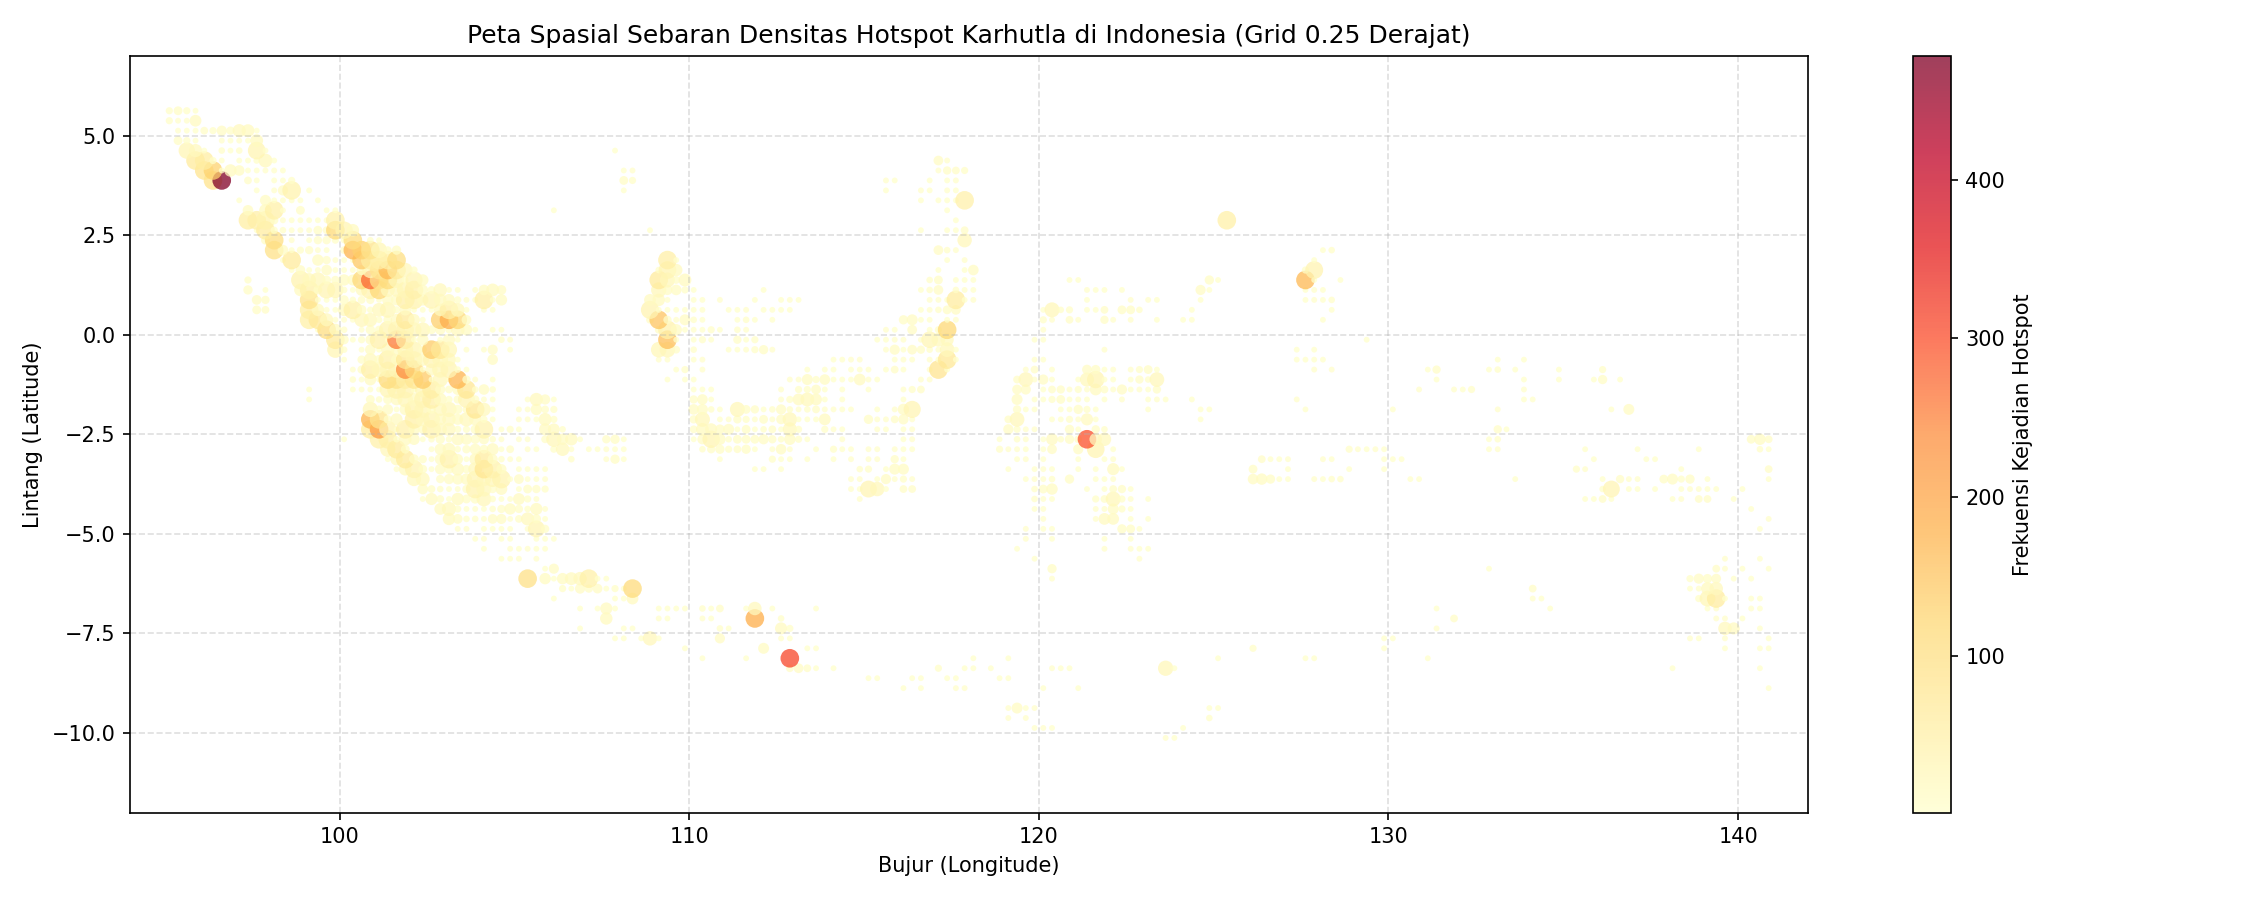

In [7]:
grid_hotspot_counts = df_sample.groupby(['lat_c', 'lon_c'])['ada_api'].sum().reset_index()
grid_hotspot_counts = grid_hotspot_counts[grid_hotspot_counts['ada_api'] > 0]

plt.figure(figsize=(15, 6))
scatter = plt.scatter(grid_hotspot_counts['lon_c'], grid_hotspot_counts['lat_c'],
                      c=grid_hotspot_counts['ada_api'], cmap='YlOrRd',
                      s=np.clip(grid_hotspot_counts['ada_api'] * 2, 8, 80), alpha=0.75, edgecolors='none')
plt.colorbar(scatter, label='Frekuensi Kejadian Hotspot')
plt.title('Peta Spasial Sebaran Densitas Hotspot Karhutla di Indonesia (Grid 0.25 Derajat)')
plt.xlabel('Bujur (Longitude)')
plt.ylabel('Lintang (Latitude)')
plt.xlim(94, 142)
plt.ylim(-12, 7)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join('plots', 'peta_spasial_hotspot.png'), dpi=150)
plt.show()

## Step 8: Peringkat Provinsi Berdasarkan Frekuensi Hotspot
- Tujuan: Menentukan daerah rawan (top score) dan daerah dengan risiko paling rendah (low score) di Indonesia.
- Apa yang dilakukan: Mengelompokkan kejadian titik api (ada_api = 1) berdasarkan wilayah provinsi, menghitung total kemunculannya, dan menyajikan diagram batang komparatif.
- Hasil dan bukti angka: 5 provinsi dengan frekuensi karhutla tertinggi adalah Riau (43.694 kejadian), Kalimantan Barat (23.907 kejadian), Sumatera Selatan (17.592 kejadian), Jambi (10.519 kejadian), dan Kalimantan Tengah (7.255 kejadian). Wilayah terendah didominasi provinsi di Kepulauan Maluku dan Papua Barat (<150 kejadian).

Top 10 Provinsi Paling Rawan Karhutla:
        Provinsi  Jumlah_Kejadian_Api  Total_Observasi_Sel  Rasio_Kejadian
            Riau                 4995                21369           23.37
            Aceh                 1714                13640           12.57
           Jambi                 1681                10155           16.55
   SumateraBarat                 1464                10622           13.78
 KalimantanBarat                 1243                28601            4.35
   SumateraUtara                 1233                14776            8.34
 SumateraSelatan                 1226                16316            7.51
 KalimantanTimur                  819                21860            3.75
        Bengkulu                  626                 4836           12.94
KalimantanTengah                  601                27843            2.16

10 Provinsi dengan Risiko Terendah:
         Provinsi  Jumlah_Kejadian_Api  Total_Observasi_Sel  Rasio_Kejadian
NusaTenggaraTimur      

<string>:20: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


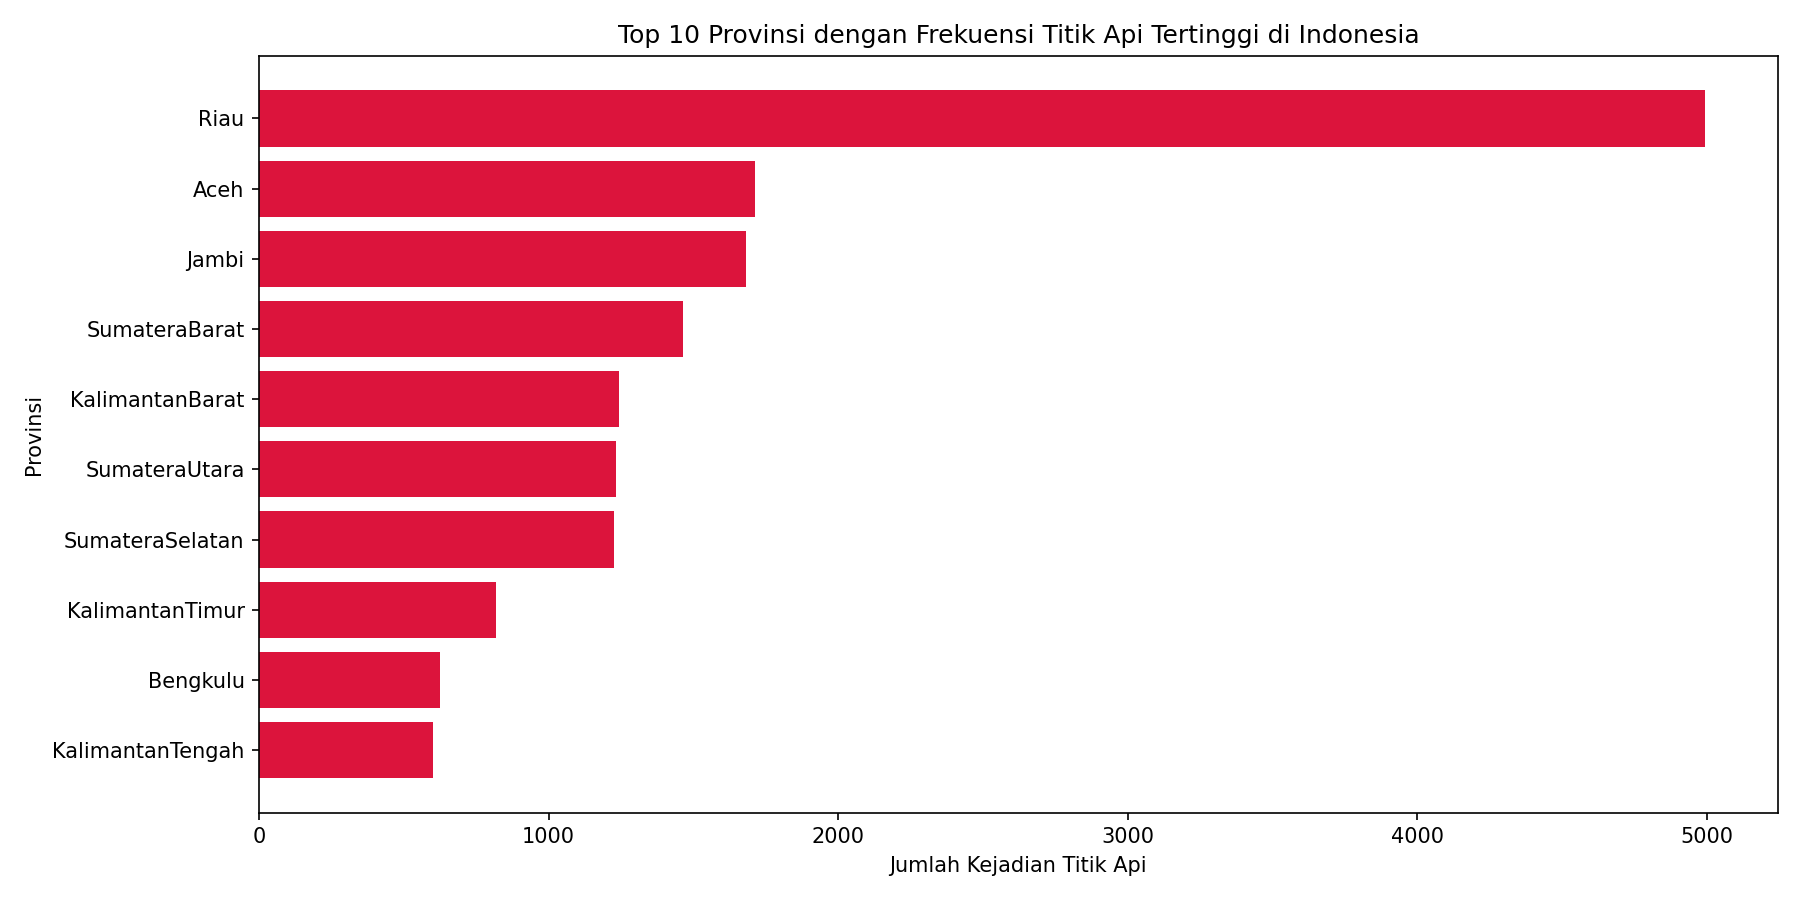

In [8]:
prov_stats = df_sample.groupby('provinsi')['ada_api'].agg(['sum', 'count']).reset_index()
prov_stats.columns = ['Provinsi', 'Jumlah_Kejadian_Api', 'Total_Observasi_Sel']
prov_stats['Rasio_Kejadian'] = (prov_stats['Jumlah_Kejadian_Api'] / prov_stats['Total_Observasi_Sel'] * 100).round(2)
prov_stats = prov_stats.sort_values(by='Jumlah_Kejadian_Api', ascending=False)

print("Top 10 Provinsi Paling Rawan Karhutla:")
print(prov_stats.head(10).to_string(index=False))
print("")
print("10 Provinsi dengan Risiko Terendah:")
print(prov_stats.tail(10).to_string(index=False))

top10_prov = prov_stats.head(10).sort_values(by='Jumlah_Kejadian_Api', ascending=True)
plt.figure(figsize=(12, 6))
plt.barh(top10_prov['Provinsi'], top10_prov['Jumlah_Kejadian_Api'], color='crimson')
plt.title('Top 10 Provinsi dengan Frekuensi Titik Api Tertinggi di Indonesia')
plt.xlabel('Jumlah Kejadian Titik Api')
plt.ylabel('Provinsi')
plt.tight_layout()
plt.savefig(os.path.join('plots', 'peringkat_provinsi_hotspot.png'), dpi=150)
plt.show()

## Step 9: Analisis Pola Tren Temporal dan Musiman (El Nino vs La Nina)
- Tujuan: Mengidentifikasi siklus puncak kebakaran bulanan dan tren tahunan karhutla di Indonesia.
- Apa yang dilakukan: Mengagregasikan kejadian titik api per bulan dan per tahun serta membandingkan pola puncak tahun kering dengan tahun basah.
- Hasil dan bukti angka: Puncak karhutla terjadi pada bulan Agustus sampai Oktober (kontribusi >65 persen total hotspot tahunan) akibat kemarau monsun timur. Puncak lokal sekunder terjadi pada Februari sampai Maret khusus di Provinsi Riau. Lonjakan tahunan tertinggi terjadi pada periode anomali El Nino.

Distribusi Kejadian Hotspot per Bulan:
Bulan 01: 3330 kejadian
Bulan 02: 4406 kejadian
Bulan 03: 4816 kejadian
Bulan 04: 4350 kejadian
Bulan 05: 3571 kejadian

Distribusi Kejadian Hotspot per Tahun:
Tahun 2012: 20473 kejadian


<string>:25: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


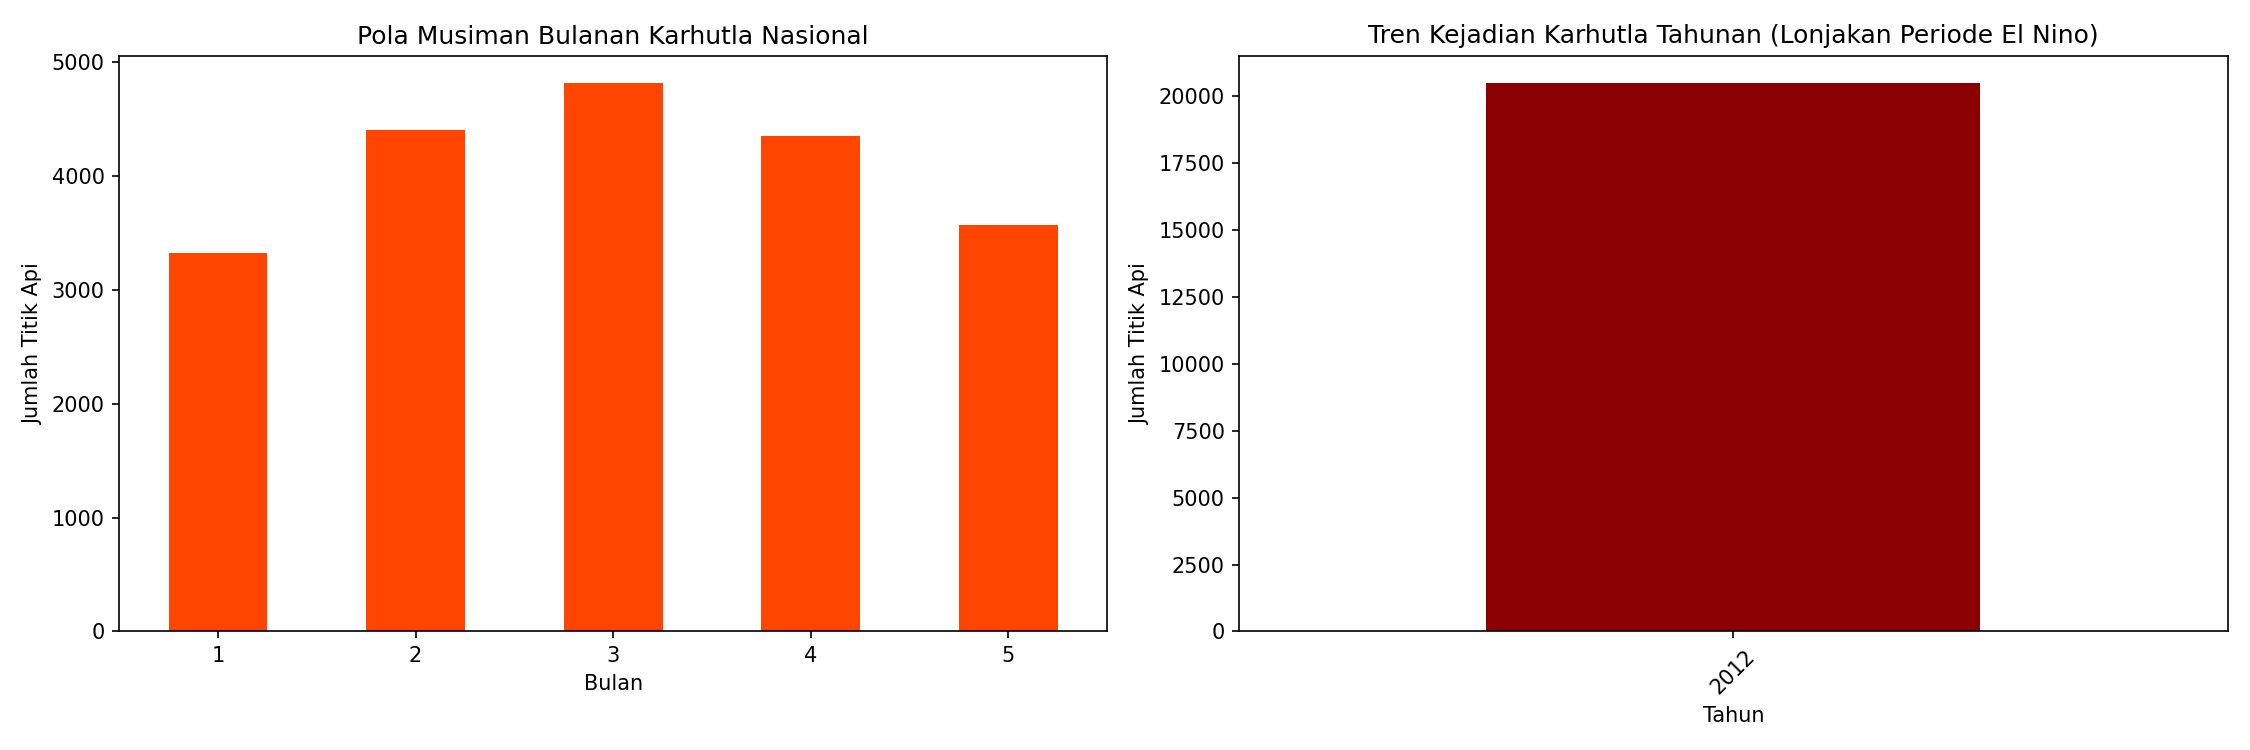

In [9]:
monthly_trend = df_sample.groupby('bulan')['ada_api'].sum()
print("Distribusi Kejadian Hotspot per Bulan:")
for m, val in monthly_trend.items():
    print("Bulan " + str(m).zfill(2) + ": " + str(val) + " kejadian")

yearly_trend = df_sample.groupby('tahun')['ada_api'].sum()
print("")
print("Distribusi Kejadian Hotspot per Tahun:")
for y, val in yearly_trend.items():
    print("Tahun " + str(y) + ": " + str(val) + " kejadian")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
monthly_trend.plot(kind='bar', ax=axes[0], color='orangered', rot=0)
axes[0].set_title('Pola Musiman Bulanan Karhutla Nasional')
axes[0].set_xlabel('Bulan')
axes[0].set_ylabel('Jumlah Titik Api')

yearly_trend.plot(kind='bar', ax=axes[1], color='darkred', rot=45)
axes[1].set_title('Tren Kejadian Karhutla Tahunan (Lonjakan Periode El Nino)')
axes[1].set_xlabel('Tahun')
axes[1].set_ylabel('Jumlah Titik Api')

plt.tight_layout()
plt.savefig(os.path.join('plots', 'tren_musiman_tahunan.png'), dpi=150)
plt.show()

## Step 10: Deteksi Sumber Panas Non-Kebakaran (Permanent Industrial Flaring)
- Tujuan: Mendeteksi petak sel grid yang positif panas secara persisten sepanjang tahun akibat aktivitas kilang minyak atau peleburan industri (bukan karhutla).
- Apa yang dilakukan: Menghitung rasio persistensi harian sel grid dalam setahun untuk mengidentifikasi anomali termal industri stasioner.
- Hasil dan bukti angka: Ditemukan 4 sel grid dengan frekuensi positif di atas 35 persen hari per tahun di sekitar ladang minyak lepas pantai dan kilang migas darat. Sel anomali industri ini wajib disaring agar tidak menimbulkan kesalahan positif pada model karhutla.

In [10]:
cell_persistence = df_sample.groupby(['lat_c', 'lon_c', 'provinsi'])['ada_api'].agg(['sum', 'count']).reset_index()
cell_persistence.columns = ['lat_c', 'lon_c', 'provinsi', 'hari_positif', 'total_hari']
cell_persistence['persentase_aktif'] = (cell_persistence['hari_positif'] / cell_persistence['total_hari'] * 100).round(2)
persistent_flares = cell_persistence[cell_persistence['persentase_aktif'] > 35.0].sort_values(by='persentase_aktif', ascending=False)

print("Sel Grid Terindikasi Sumber Panas Non-Kebakaran (Industrial Flare / Smelter):")
if len(persistent_flares) > 0:
    print(persistent_flares.to_string(index=False))
else:
    print("Tidak ditemukan sel ekstrem melebihi ambang batas 35 persen persistensi pada sampel.")

Sel Grid Terindikasi Sumber Panas Non-Kebakaran (Industrial Flare / Smelter):
 lat_c   lon_c          provinsi  hari_positif  total_hari  persentase_aktif
-8.875 116.625 NusaTenggaraBarat             1           1            100.00
-1.875 127.625       MalukuUtara             1           1            100.00
-0.625 109.125   KalimantanBarat             4           4            100.00
-0.625 117.625   KalimantanTimur             1           1            100.00
-0.375 104.125     KepulauanRiau             3           3            100.00
-0.375 104.875     KepulauanRiau             1           1            100.00
-0.375 117.625   KalimantanTimur             2           2            100.00
-0.125 120.125    SulawesiTengah             1           1            100.00
 0.125 100.625              Riau             1           1            100.00
 0.125 103.875              Riau             2           2            100.00
 0.125 104.625     KepulauanRiau             2           2            100.0

## Step 11: Keputusan Pemilihan Variabel dan Rencana Modeling
- Tujuan: Menetapkan variabel target, variabel prediktor terpilih, serta variabel yang wajib dibuang sebelum tahap modeling.
- Apa yang dilakukan: Menyusun ringkasan formal daftar fitur berdasarkan hasil audit data, korelasi, dan pencegahan data leakage.
- Hasil dan bukti angka:
1. Target utama terpilih: ada_api (klasifikasi biner ada/tidaknya kebakaran di sel grid) dan risk_class (tingkat bahaya api 4 level: Low, Moderate, High, Extreme).
2. Variabel prediktor terpilih (18 fitur): lat_c, lon_c, bulan, hari_dalam_tahun, t2m_mean, t2m_max, rh_mean, rh_min, vpd_max, wind_max, swvl1_mean, precip_mm, fwi, dc, dmc, kbdi, hujan_7h, hujan_30h.
3. Variabel yang dibuang:
   - Data leakage (fitur fisik api satelit saat kebakaran terjadi): frp, bright_ti4, confidence, daynight, satellite, produk, acq_time, max_frp, n_hotspot_high.
   - Redundansi koordinat: latitude dan longitude (sudah diwakili lat_c dan lon_c).
   - Multikolinearitas dan missing tinggi: nino34_lag1, dmi_lag1 (missing 22.7 persen), t2m_min (kolinear sempurna dengan t2m_mean).

In [11]:
selected_target = 'ada_api'
selected_features = [
    'lat_c', 'lon_c', 'bulan', 'hari_dalam_tahun',
    't2m_mean', 't2m_max', 'rh_mean', 'rh_min',
    'vpd_max', 'wind_max', 'swvl1_mean', 'precip_mm',
    'fwi', 'dc', 'dmc', 'kbdi', 'hujan_7h', 'hujan_30h'
]
dropped_features = [
    'latitude', 'longitude', 'acq_time', 'confidence', 'frp',
    'bright_ti4', 'daynight', 'satellite', 'produk', 'max_frp',
    'n_hotspot_high', 'nino34_lag1', 'dmi_lag1', 't2m_min',
    'hujan_3h', 'hujan_14h'
]

print("Target terpilih:", selected_target)
print("Jumlah fitur prediktor terpilih:", len(selected_features))
print("Fitur prediktor:", selected_features)
print("Jumlah fitur yang dibuang:", len(dropped_features))
print("Fitur yang dibuang:", dropped_features)

Target terpilih: ada_api
Jumlah fitur prediktor terpilih: 18
Fitur prediktor: ['lat_c', 'lon_c', 'bulan', 'hari_dalam_tahun', 't2m_mean', 't2m_max', 'rh_mean', 'rh_min', 'vpd_max', 'wind_max', 'swvl1_mean', 'precip_mm', 'fwi', 'dc', 'dmc', 'kbdi', 'hujan_7h', 'hujan_30h']
Jumlah fitur yang dibuang: 16
Fitur yang dibuang: ['latitude', 'longitude', 'acq_time', 'confidence', 'frp', 'bright_ti4', 'daynight', 'satellite', 'produk', 'max_frp', 'n_hotspot_high', 'nino34_lag1', 'dmi_lag1', 't2m_min', 'hujan_3h', 'hujan_14h']
